
# Nettoyage des données olympiques

**AMA — PIIA Cohorte 2 — Machine Learning**

**Binôme :** EGUE Richnel et AVADRA Martial

**Domaine :** Sport — Athlètes des Jeux olympiques.

## 1. Contexte et objectifs

Ce notebook porte sur le nettoyage du jeu de données historique
des athlètes ayant participé aux Jeux olympiques entre 1896 et 2016.

Le fichier utilisé est `athlete_events.csv`, téléchargé depuis Kaggle.

L'objectif est de préparer des données fiables pour étudier :

- L'âge des athlètes.
- Leur taille et leur poids.
- La répartition des médailles.
- Les participations et performances par pays.

## 2. Méthodologie

Le travail sera organisé en trois grandes phases :

1. Diagnostic initial : comprendre et mesurer les problèmes de qualité.
2. Nettoyage : corriger les problèmes identifiés en justifiant chaque choix.
3. Évaluation finale : comparer les indicateurs avant et après nettoyage.

**Important :** aucune transformation n'est effectuée dans cette première
partie. Nous cherchons d'abord à comprendre les données.

Le fichier original doit rester intact.



## 3. Importation des bibliothèques

Nous utilisons :

- `pandas` pour la manipulation des données ;
- `numpy` pour les opérations numériques ;
- `matplotlib` pour les visualisations ;
- `pathlib` pour gérer les chemins de fichiers.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Paramètres d'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", lambda value: f"{value:.2f}")

# Déterminer automatiquement la racine du projet
ROOT_DIR = Path.cwd()

if not (ROOT_DIR / "data" / "raw" / "athlete_events.csv").exists():
    if (ROOT_DIR.parent / "data" / "raw" / "athlete_events.csv").exists():
        ROOT_DIR = ROOT_DIR.parent

DATA_PATH = ROOT_DIR / "data" / "raw" / "athlete_events.csv"
REPORTS_DIR = ROOT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Vérifier la présence du fichier
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH}\n"
        "Vérifiez que le dataset est bien placé dans data/raw/."
    )

print("Bibliothèques importées avec succès.")
print(f"Répertoire du projet : {ROOT_DIR}")
print(f"Fichier source : {DATA_PATH}")


Bibliothèques importées avec succès.
Répertoire du projet : D:\Projet\exercice_ama
Fichier source : D:\Projet\exercice_ama\data\raw\athlete_events.csv



## 4. Chargement des données originales

Nous chargeons le fichier CSV avec Pandas.

Le paramètre `low_memory=False` permet de réaliser l'analyse des types
de colonnes sur l'ensemble du fichier.

Pandas interprète notamment les marqueurs tels que `NA` comme des
valeurs manquantes.

Nous conservons deux références :

- `df_original` : copie chargée du fichier source, que nous ne modifierons pas.
- `df` : copie de travail destinée aux analyses.


In [2]:

# Charger les données originales
df_original = pd.read_csv(DATA_PATH, low_memory=False)

# Créer une copie de travail
df = df_original.copy(deep=True)

print("Chargement terminé.")
print(f"Nombre de lignes : {df.shape[0]:,}")
print(f"Nombre de colonnes : {df.shape[1]}")
print(f"Consommation mémoire : {df.memory_usage(deep=True).sum() / (1024**2):.2f} Mo")


Chargement terminé.
Nombre de lignes : 271,116
Nombre de colonnes : 15
Consommation mémoire : 158.85 Mo



## 5. Première observation des données

Nous examinons les premières et les dernières observations afin de
comprendre la structure des enregistrements.

Une ligne représente une participation d'un athlète à une épreuve
lors d'une édition des Jeux olympiques.


In [3]:

print("Premières observations :")
display(df.head(10))

print("\nDernières observations :")
display(df.tail(5))


Premières observations :


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.00,180.00,80.00,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.00,170.00,60.00,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.00,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.00,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.00,185.00,82.00,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN
5,5,Christine Jacoba Aaftink,F,21.00,185.00,82.00,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,"Speed Skating Women's 1,000 metres",NaN
6,5,Christine Jacoba Aaftink,F,25.00,185.00,82.00,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,Speed Skating Women's 500 metres,NaN
7,5,Christine Jacoba Aaftink,F,25.00,185.00,82.00,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,"Speed Skating Women's 1,000 metres",NaN
8,5,Christine Jacoba Aaftink,F,27.00,185.00,82.00,Netherlands,NED,1994 Winter,1994,Winter,Lillehammer,Speed Skating,Speed Skating Women's 500 metres,NaN
9,5,Christine Jacoba Aaftink,F,27.00,185.00,82.00,Netherlands,NED,1994 Winter,1994,Winter,Lillehammer,Speed Skating,"Speed Skating Women's 1,000 metres",NaN



Dernières observations :


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
271111,135569,Andrzej ya,M,29.00,179.00,89.00,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN
271112,135570,Piotr ya,M,27.00,176.00,59.00,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN
271113,135570,Piotr ya,M,27.00,176.00,59.00,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN
271114,135571,Tomasz Ireneusz ya,M,30.00,185.00,96.00,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN
271115,135571,Tomasz Ireneusz ya,M,34.00,185.00,96.00,Poland,POL,2002 Winter,2002,Winter,Salt Lake City,Bobsleigh,Bobsleigh Men's Four,NaN



## 6. État structurel du jeu de données

Nous examinons :

- Les dimensions du jeu de données.
- Les noms des colonnes.
- Les types de données.
- Le nombre de valeurs non manquantes.
- Le nombre de valeurs distinctes.

Cette étape permettra notamment de vérifier si les variables sont
stockées dans des types adaptés à leur utilisation.


In [4]:

# Informations générales
print("Dimensions :", df.shape)
print("\nColonnes :")
print(df.columns.tolist())

print("\nInformations détaillées :")
df.info()

# Tableau récapitulatif de la structure
structure_summary = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs_non_manquantes": df.notna().sum(),
    "valeurs_distinctes": df.nunique(dropna=True)
})

display(structure_summary)


Dimensions : (271116, 15)

Colonnes :
['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games', 'Year', 'Season', 'City', 'Sport', 'Event', 'Medal']

Informations détaillées :
<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  str    
 2   Sex     271116 non-null  str    
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  str    
 7   NOC     271116 non-null  str    
 8   Games   271116 non-null  str    
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  str    
 11  City    271116 non-null  str    
 12  Sport   271116 non-null  str    
 13  Event   271116 non-null  str    
 14  Medal   39783 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 31.0 MB


,type,valeurs_non_manquantes,valeurs_distinctes
ID,int64,271116,135571
Name,str,271116,134732
Sex,str,271116,2
Age,float64,261642,74
Height,float64,210945,95
Weight,float64,208241,220
Team,str,271116,1184
NOC,str,271116,230
Games,str,271116,51
Year,int64,271116,35



## 7. Analyse des valeurs manquantes

Nous calculons, pour chaque colonne :

- Le nombre de valeurs manquantes.
- Le pourcentage de valeurs manquantes.

Cette mesure est importante pour décider ultérieurement si une
suppression, une imputation ou une conservation est justifiée.

### Attention à la colonne Medal

Une valeur manquante dans `Medal` signifie généralement que l'athlète
n'a remporté aucune médaille.

Il ne faut donc pas automatiquement considérer ces valeurs comme
des erreurs à corriger. Nous les mesurerons, mais leur interprétation
sera différente de celle des valeurs manquantes dans `Age`, `Height`
ou `Weight`.


In [5]:

# Calculer le nombre et le pourcentage de valeurs manquantes
missing_summary = pd.DataFrame({
    "valeurs_manquantes": df.isna().sum(),
    "pourcentage_manquant": (df.isna().mean() * 100)
})

missing_summary = missing_summary.sort_values(
    by="pourcentage_manquant",
    ascending=False
)

print("Bilan des valeurs manquantes :")
display(missing_summary)

print("\nNombre total de cellules manquantes :", int(df.isna().sum().sum()))
print("Pourcentage global de cellules manquantes :", f"{df.isna().mean().mean() * 100:.2f}%")

# Observation particulière de la colonne Medal
if "Medal" in df.columns:
    print("\nRépartition de la colonne Medal :")
    display(df["Medal"].value_counts(dropna=False).to_frame("effectif"))


Bilan des valeurs manquantes :


,valeurs_manquantes,pourcentage_manquant
Medal,231333,85.33
Weight,62875,23.19
Height,60171,22.19
Age,9474,3.49
Sex,0,0.00
ID,0,0.00
Name,0,0.00
Team,0,0.00
NOC,0,0.00
Year,0,0.00



Nombre total de cellules manquantes : 363853
Pourcentage global de cellules manquantes : 8.95%

Répartition de la colonne Medal :


,effectif
Medal,
NaN,231333
Gold,13372
Bronze,13295
Silver,13116



## 8. Recherche des doublons

Nous distinguons deux notions.

**Doublons exacts :** deux lignes dont toutes les colonnes sont identiques.

**Répétitions d'identifiants :** un même athlète apparaît sur plusieurs
lignes parce qu'il a participé à plusieurs épreuves ou éditions.

La répétition d'un identifiant `ID` n'est donc pas automatiquement
un doublon à supprimer.


In [6]:

# Rechercher les lignes intégralement dupliquées
exact_duplicates = int(df.duplicated().sum())

print("Nombre de doublons exacts :", exact_duplicates)

if exact_duplicates > 0:
    print("\nExemples de lignes dupliquées :")
    display(df[df.duplicated(keep=False)].head(20))
else:
    print("Aucun doublon exact détecté.")

# Étudier les identifiants des athlètes
if "ID" in df.columns:
    athlete_counts = df.groupby("ID").size()

    print("\nNombre d'athlètes distincts :", df["ID"].nunique())
    print("Nombre d'athlètes présents sur plusieurs lignes :", int((athlete_counts > 1).sum()))
    print("Nombre de participations au-delà de la première ligne par athlète :",
          int(athlete_counts.sum() - len(athlete_counts)))

    print("\nDistribution du nombre de lignes par athlète :")
    display(athlete_counts.describe().to_frame("nombre_de_lignes"))


Nombre de doublons exacts : 1385

Exemples de lignes dupliquées :


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
1251,704,Dsir Antoine Acket,M,27.00,NaN,NaN,Belgium,BEL,1932 Summer,1932,Summer,Los Angeles,Art Competitions,"Art Competitions Mixed Painting, Unknown Event",NaN
1252,704,Dsir Antoine Acket,M,27.00,NaN,NaN,Belgium,BEL,1932 Summer,1932,Summer,Los Angeles,Art Competitions,"Art Competitions Mixed Painting, Unknown Event",NaN
4281,2449,William Truman Aldrich,M,48.00,NaN,NaN,United States,USA,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Painting, Drawings And ...",NaN
4282,2449,William Truman Aldrich,M,48.00,NaN,NaN,United States,USA,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Painting, Drawings And ...",NaN
4283,2449,William Truman Aldrich,M,48.00,NaN,NaN,United States,USA,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Painting, Drawings And ...",NaN
4861,2777,Hermann Reinhard Alker,M,43.00,NaN,NaN,Germany,GER,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Architecture, Designs F...",NaN
4862,2777,Hermann Reinhard Alker,M,43.00,NaN,NaN,Germany,GER,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Architecture, Designs F...",NaN
4863,2777,Hermann Reinhard Alker,M,43.00,NaN,NaN,Germany,GER,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Architecture, Architect...",NaN
4864,2777,Hermann Reinhard Alker,M,43.00,NaN,NaN,Germany,GER,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Architecture, Architect...",NaN
4866,2777,Hermann Reinhard Alker,M,51.00,NaN,NaN,Germany,GER,1936 Summer,1936,Summer,Berlin,Art Competitions,"Art Competitions Mixed Architecture, Unknown E...",NaN



Nombre d'athlètes distincts : 135571
Nombre d'athlètes présents sur plusieurs lignes : 57670
Nombre de participations au-delà de la première ligne par athlète : 135545

Distribution du nombre de lignes par athlète :


,nombre_de_lignes
count,135571.00
mean,2.00
std,1.99
min,1.00
25%,1.00
50%,1.00
75%,2.00
max,58.00



## 9. Analyse descriptive des variables numériques

Nous étudions les variables :

- `Age` : âge de l'athlète.
- `Height` : taille de l'athlète.
- `Weight` : poids de l'athlète.

Les statistiques incluent notamment la moyenne, l'écart-type,
les quartiles, le minimum et le maximum.

Elles permettront de repérer les distributions inhabituelles
et les valeurs extrêmes à examiner.


In [7]:

numeric_columns = ["Age", "Height", "Weight"]

numeric_summary = df[numeric_columns].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

display(numeric_summary)

print("\nValeurs non positives :")
for column in numeric_columns:
    print(f"{column} : {(df[column] <= 0).sum()}")


,count,mean,std,min,1%,25%,50%,75%,99%,max
Age,261642.00,25.56,6.39,10.00,15.00,21.00,24.00,28.00,48.00,97.00
Height,210945.00,175.34,10.52,127.00,150.00,168.00,175.00,183.00,200.00,226.00
Weight,208241.00,70.70,14.35,25.00,43.00,60.00,70.00,79.00,114.00,214.00



Valeurs non positives :
Age : 0
Height : 0
Weight : 0



## 10. Analyse des variables catégorielles

Nous étudions les modalités des principales variables qualitatives :

- `Sex` : sexe enregistré.
- `Season` : saison des Jeux.
- `Medal` : médaille obtenue.
- `NOC` : code du comité olympique national.
- `Sport` : discipline sportive.

Cette analyse permet de repérer les catégories rares, les valeurs
inattendues et les éventuelles incohérences.


In [8]:

categorical_columns = ["Sex", "Season", "Medal", "NOC", "Sport"]

for column in categorical_columns:
    print(f"\n{'=' * 60}")
    print(f"Variable : {column}")
    print(f"Nombre de modalités distinctes : {df[column].nunique(dropna=True)}")
    display(df[column].value_counts(dropna=False).head(20).to_frame("effectif"))



Variable : Sex
Nombre de modalités distinctes : 2


,effectif
Sex,
M,196594
F,74522



Variable : Season
Nombre de modalités distinctes : 2


,effectif
Season,
Summer,222552
Winter,48564



Variable : Medal
Nombre de modalités distinctes : 3


,effectif
Medal,
NaN,231333
Gold,13372
Bronze,13295
Silver,13116



Variable : NOC
Nombre de modalités distinctes : 230


,effectif
NOC,
USA,18853
FRA,12758
GBR,12256
ITA,10715
GER,9830
CAN,9733
JPN,8444
SWE,8339
AUS,7638



Variable : Sport
Nombre de modalités distinctes : 66


,effectif
Sport,
Athletics,38624
Gymnastics,26707
Swimming,23195
Shooting,11448
Cycling,10859
Fencing,10735
Rowing,10595
Cross Country Skiing,9133
Alpine Skiing,8829



## 11. Visualisation des valeurs manquantes

Nous représentons le pourcentage de valeurs manquantes par colonne.

Ce graphique permet de repérer rapidement les variables les plus
affectées par les problèmes de complétude.

Le graphique est également enregistré dans `reports/figures/`.


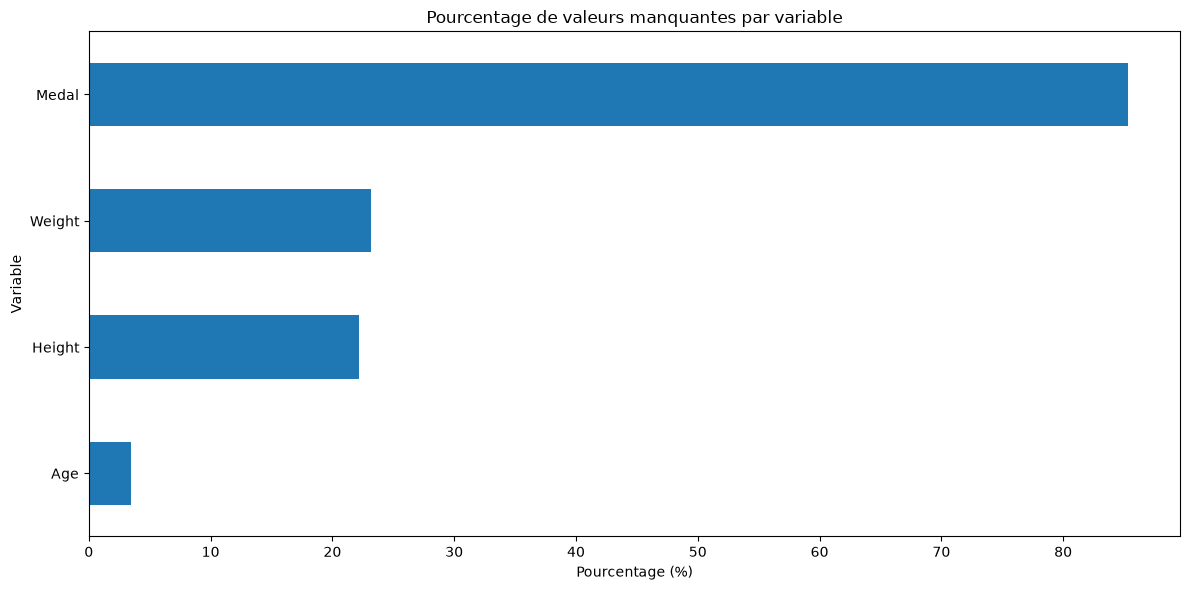

Graphique enregistré : D:\Projet\exercice_ama\reports\figures\01_valeurs_manquantes_initiales.png


In [9]:

missing_to_plot = missing_summary[
    missing_summary["valeurs_manquantes"] > 0
]["pourcentage_manquant"]

if not missing_to_plot.empty:
    fig, ax = plt.subplots(figsize=(12, 6))

    missing_to_plot.sort_values().plot(
        kind="barh",
        ax=ax
    )

    ax.set_title("Pourcentage de valeurs manquantes par variable")
    ax.set_xlabel("Pourcentage (%)")
    ax.set_ylabel("Variable")

    plt.tight_layout()

    figure_path = FIGURES_DIR / "01_valeurs_manquantes_initiales.png"
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Graphique enregistré :", figure_path)
else:
    print("Aucune valeur manquante détectée.")



## 12. Distribution des variables numériques

Nous visualisons la distribution de l'âge, de la taille et du poids.

Ces histogrammes permettront de comprendre la forme des distributions
et de repérer les observations situées très loin des valeurs centrales.

Une valeur extrême n'est cependant pas automatiquement une erreur :
elle devra être examinée dans son contexte.


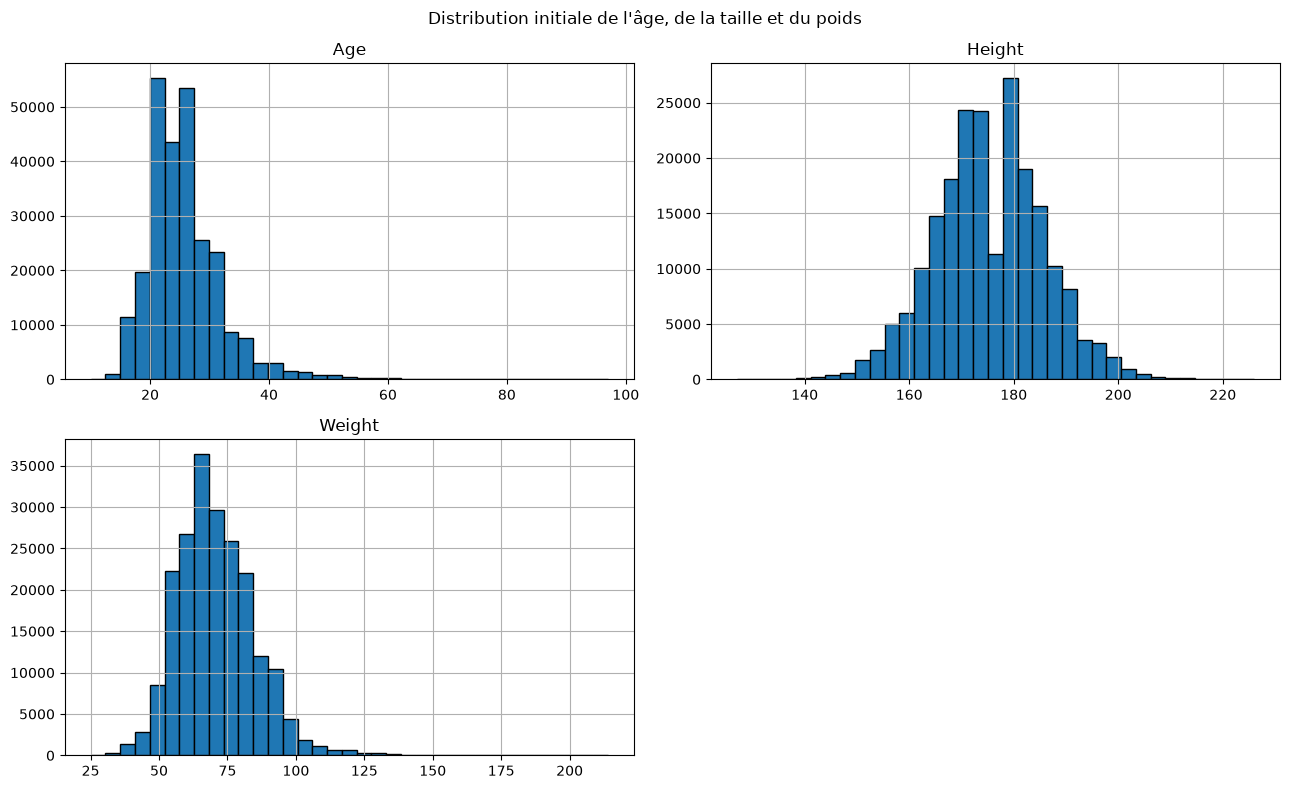

Graphique enregistré : D:\Projet\exercice_ama\reports\figures\02_distributions_numeriques_initiales.png


In [10]:

axes = df[numeric_columns].hist(
    figsize=(13, 8),
    bins=35,
    edgecolor="black"
)

plt.suptitle("Distribution initiale de l'âge, de la taille et du poids")
plt.tight_layout()

figure_path = FIGURES_DIR / "02_distributions_numeriques_initiales.png"

plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Graphique enregistré :", figure_path)



## 13. Détection exploratoire des valeurs aberrantes

Nous utilisons ici la méthode de l'intervalle interquartile (IQR).

Pour chaque variable numérique :

- Q1 représente le premier quartile.
- Q3 représente le troisième quartile.
- IQR = Q3 - Q1.

Les bornes exploratoires sont :

- Borne inférieure : Q1 - 1,5 × IQR.
- Borne supérieure : Q3 + 1,5 × IQR.

Une valeur en dehors de ces bornes est considérée comme une observation
statistiquement atypique.

**Attention :** cette méthode ne prouve pas qu'une valeur est fausse.
Elle identifie uniquement des observations à examiner.


In [11]:

outlier_results = []

for column in numeric_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df[column] < lower_bound)
        | (df[column] > upper_bound)
    )

    outlier_results.append({
        "variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "borne_inferieure": lower_bound,
        "borne_superieure": upper_bound,
        "nombre_candidats": int(outlier_mask.sum()),
        "pourcentage": float(outlier_mask.mean() * 100)
    })

    print(f"\nObservations atypiques pour {column} :")
    print("Nombre détecté :", int(outlier_mask.sum()))

    sample_columns = [
        "ID", "Name", "Sex", column,
        "Team", "Year", "Sport", "Event"
    ]

    display(
        df.loc[outlier_mask, sample_columns]
        .sort_values(by=column)
        .head(10)
    )

outlier_summary = pd.DataFrame(outlier_results)

print("\nSynthèse des valeurs statistiquement atypiques :")
display(outlier_summary)



Observations atypiques pour Age :
Nombre détecté : 10317


,ID,Name,Sex,Age,Team,Year,Sport,Event
142882,71691,Dimitrios Loundras,M,10.00,Ethnikos Gymnastikos Syllogos,1896,Gymnastics,"Gymnastics Men's Parallel Bars, Teams"
36299,18649,Kyle Carter,M,39.00,Canada,2008,Equestrianism,"Equestrianism Mixed Three-Day Event, Individual"
247533,123926,Juan Antonio Valencia,M,39.00,El Salvador,1968,Shooting,"Shooting Mixed Small-Bore Rifle, Three Positio..."
247519,123918,Anita Valen (-de Vries),F,39.00,Norway,2008,Cycling,"Cycling Women's Road Race, Individual"
36917,18981,Roberto Marcelo Castrillo Garca,M,39.00,Cuba,1980,Shooting,Shooting Mixed Skeet
37185,19121,Fernando Jos Pereira Marqus Cavaleiro,M,39.00,Portugal,1956,Equestrianism,"Equestrianism Men's Three-Day Event, Team"
37184,19121,Fernando Jos Pereira Marqus Cavaleiro,M,39.00,Portugal,1956,Equestrianism,"Equestrianism Men's Three-Day Event, Individual"
35527,18263,Per Hjalmar Ludvig Carleson,M,39.00,Sweden,1956,Fencing,"Fencing Men's epee, Team"
35526,18263,Per Hjalmar Ludvig Carleson,M,39.00,Sweden,1956,Fencing,"Fencing Men's epee, Individual"
37875,19462,Spartaco Cesaretti,M,39.00,San Marino,1960,Shooting,"Shooting Men's Free Pistol, 50 metres"



Observations atypiques pour Height :
Nombre détecté : 1338


,ID,Name,Sex,Height,Team,Year,Sport,Event
164821,82769,Lyton Levison Mphande,M,127.00,Malawi,1988,Boxing,Boxing Men's Light-Welterweight
29336,15150,Rosario Briones,F,127.00,Mexico,1968,Gymnastics,Gymnastics Women's Horse Vault
29337,15150,Rosario Briones,F,127.00,Mexico,1968,Gymnastics,Gymnastics Women's Uneven Bars
29338,15150,Rosario Briones,F,127.00,Mexico,1968,Gymnastics,Gymnastics Women's Balance Beam
29335,15150,Rosario Briones,F,127.00,Mexico,1968,Gymnastics,Gymnastics Women's Floor Exercise
29334,15150,Rosario Briones,F,127.00,Mexico,1968,Gymnastics,Gymnastics Women's Team All-Around
29333,15150,Rosario Briones,F,127.00,Mexico,1968,Gymnastics,Gymnastics Women's Individual All-Around
180615,90772,Helman Palije,M,128.00,Malawi,1988,Boxing,Boxing Men's Middleweight
220270,110638,Boston Simbeye,M,130.00,Malawi,1988,Boxing,Boxing Men's Welterweight
159934,80255,Salvador Miranda,M,130.00,Nicaragua,1972,Boxing,Boxing Men's Flyweight



Observations atypiques pour Weight :
Nombre détecté : 3237


,ID,Name,Sex,Weight,Team,Year,Sport,Event
40854,21049,Choi Myong-Hui,F,25.00,North Korea,1980,Gymnastics,Gymnastics Women's Balance Beam
40851,21049,Choi Myong-Hui,F,25.00,North Korea,1980,Gymnastics,Gymnastics Women's Floor Exercise
40852,21049,Choi Myong-Hui,F,25.00,North Korea,1980,Gymnastics,Gymnastics Women's Horse Vault
40853,21049,Choi Myong-Hui,F,25.00,North Korea,1980,Gymnastics,Gymnastics Women's Uneven Bars
40850,21049,Choi Myong-Hui,F,25.00,North Korea,1980,Gymnastics,Gymnastics Women's Team All-Around
40849,21049,Choi Myong-Hui,F,25.00,North Korea,1980,Gymnastics,Gymnastics Women's Individual All-Around
268586,134370,"Albert Ferdinand ""Al"" Zerhusen",M,28.00,United States,1956,Football,Football Men's Football
264541,132383,Kana Yamawaki,F,28.00,Japan,2000,Gymnastics,Gymnastics Women's Horse Vault
264540,132383,Kana Yamawaki,F,28.00,Japan,2000,Gymnastics,Gymnastics Women's Floor Exercise
109864,55553,Anita Jokiel,F,28.00,Poland,1980,Gymnastics,Gymnastics Women's Team All-Around



Synthèse des valeurs statistiquement atypiques :


,variable,Q1,Q3,IQR,borne_inferieure,borne_superieure,nombre_candidats,pourcentage
0,Age,21.00,28.00,7.00,10.50,38.50,10317,3.81
1,Height,168.00,183.00,15.00,145.50,205.50,1338,0.49
2,Weight,60.00,79.00,19.00,31.50,107.50,3237,1.19



## 14. Première conclusion du diagnostic

À la fin de cette exploration, nous devons être capables de répondre
aux questions suivantes :

1. Quelles sont les dimensions exactes du dataset ?
2. Quelles colonnes contiennent des valeurs manquantes ?
3. Quelles variables sont les plus touchées ?
4. Les doublons exacts existent-ils ?
5. Pourquoi les répétitions de `ID` ne doivent-elles pas être
   automatiquement supprimées ?
6. Quelles observations atypiques ont été détectées ?
7. Pourquoi les valeurs manquantes de `Medal` doivent-elles être
   interprétées différemment ?

### Décisions de nettoyage

Aucune suppression, imputation ou modification des données n'a été
effectuée dans cette première partie.

Les décisions seront prises après interprétation des résultats
du diagnostic.

**La prochaine partie portera sur la stratégie de nettoyage et
la justification de chaque transformation.**


<!-- CONSOLIDATION NETTOYAGE FINAL -->

# PARTIE II — ANALYSE APPROFONDIE ET NETTOYAGE

Cette deuxième partie approfondit le diagnostic initial, définit
les corrections justifiées et vérifie la qualité du fichier produit.

Le fichier original reste notre référence. Les transformations
sont effectuées sur une copie de travail.


## 15. Analyse des valeurs manquantes selon la période historique

L'analyse globale ne suffit pas toujours à comprendre les absences.

Nous étudions donc les taux de valeurs manquantes de l'âge, de la
taille et du poids selon cinq périodes historiques.

Cette analyse permet de vérifier si la complétude des données
évolue avec le temps.


In [12]:
physical_columns = ["Age", "Height", "Weight"]

period_labels = [
    "1896-1920",
    "1921-1950",
    "1951-1980",
    "1981-2000",
    "2001-2016",
]

# Créer une copie pour ne pas modifier le dataset original.
df_period = df.copy()

df_period["Periode"] = pd.cut(
    df_period["Year"],
    bins=[1890, 1920, 1950, 1980, 2000, 2020],
    labels=period_labels,
    include_lowest=True,
)

missing_by_period = (
    df_period.groupby("Periode", observed=False)[physical_columns]
    .agg(lambda column: column.isna().mean() * 100)
    .round(2)
)

print("Pourcentage de valeurs manquantes par période :")
display(missing_by_period)

missing_by_period.to_csv(
    REPORTS_DIR / "missing_values_by_period.csv"
)


Pourcentage de valeurs manquantes par période :


,Age,Height,Weight
Periode,,,
1896-1920,21.57,84.54,87.90
1921-1950,12.98,81.26,86.10
1951-1980,2.15,18.95,19.32
1981-2000,0.50,9.05,8.97
2001-2016,0.00,0.82,1.52


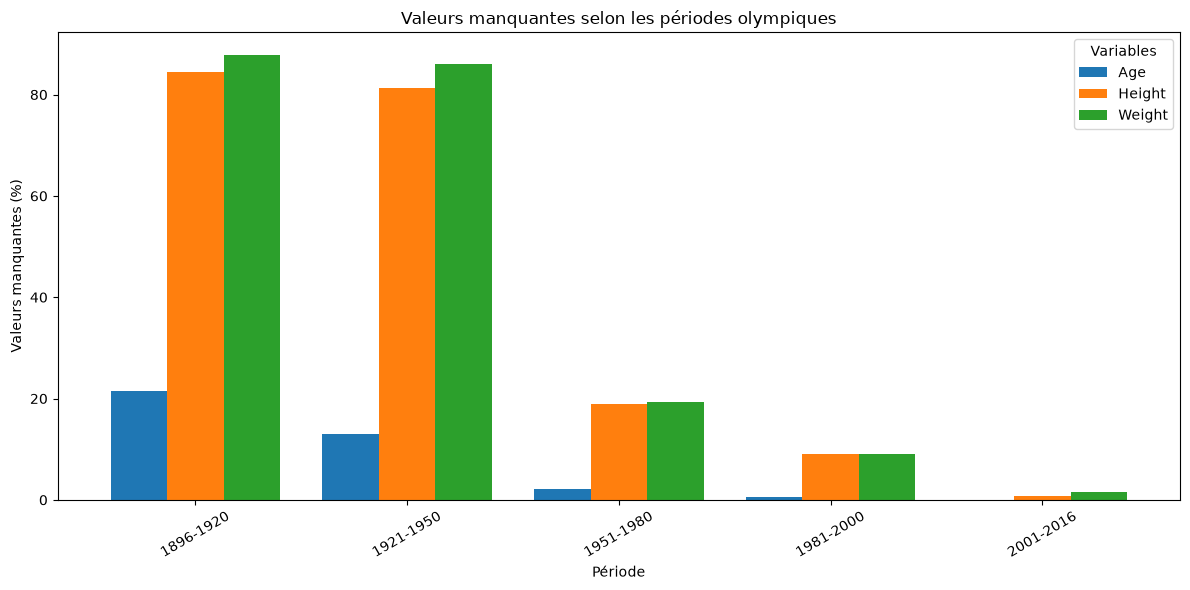

In [13]:
# Visualiser l'évolution des valeurs manquantes selon les périodes.
ax = missing_by_period.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Valeurs manquantes selon les périodes olympiques")
ax.set_xlabel("Période")
ax.set_ylabel("Valeurs manquantes (%)")
ax.legend(title="Variables")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### Interprétation

Les résultats montrent une forte dépendance entre la période historique
et la disponibilité des informations physiques.

Entre 1896 et 1920 :

- 21,57 % des âges sont manquants ;
- 84,54 % des tailles sont manquantes ;
- 87,90 % des poids sont manquants.

Entre 2001 et 2016, ces taux descendent respectivement à 0 %,
0,82 % et 1,52 %.

Cette évolution suggère que les informations physiques étaient
moins systématiquement recueillies ou documentées dans les premières
éditions olympiques.

Une imputation par moyenne globale risquerait donc de masquer
ces différences historiques.


## 16. Analyse des valeurs manquantes selon le sport

Les caractéristiques physiques des athlètes peuvent également
être documentées différemment selon les disciplines.

Nous calculons le pourcentage de valeurs manquantes pour chaque sport,
ainsi que le nombre de participations correspondant.


In [14]:
missing_by_sport = (
    df.groupby("Sport")[physical_columns]
    .agg(lambda column: column.isna().mean() * 100)
    .round(2)
)

missing_by_sport["Nombre_participations"] = (
    df.groupby("Sport").size()
)

missing_by_sport = missing_by_sport.sort_values(
    by="Nombre_participations",
    ascending=False
)

print("Vingt sports ayant le plus de participations :")
display(missing_by_sport.head(20))

missing_by_sport.to_csv(
    REPORTS_DIR / "missing_values_by_sport.csv"
)


Vingt sports ayant le plus de participations :


,Age,Height,Weight,Nombre_participations
Sport,,,,
Athletics,2.89,14.80,15.59,38624
Gymnastics,4.41,30.12,31.35,26707
Swimming,2.26,17.44,18.93,23195
Shooting,7.17,33.01,36.23,11448
Cycling,6.24,26.55,27.89,10859
Fencing,6.66,35.15,39.08,10735
Rowing,4.96,25.25,25.13,10595
Cross Country Skiing,0.38,16.03,17.48,9133
Alpine Skiing,0.88,27.58,28.08,8829


## 17. Évolution annuelle des valeurs manquantes

Nous examinons également l'évolution des absences année par année.

Cette analyse complète la comparaison par grandes périodes et permet
d'identifier les années pour lesquelles les informations sont
particulièrement incomplètes.


In [15]:
missing_by_year = (
    df.groupby("Year")[physical_columns]
    .agg(lambda column: column.isna().mean() * 100)
    .round(2)
)

print("Premières années :")
display(missing_by_year.head(10))

print("Dernières années :")
display(missing_by_year.tail(10))

missing_by_year.to_csv(
    REPORTS_DIR / "missing_values_by_year.csv"
)


Premières années :


,Age,Height,Weight
Year,,,
1896,42.89,87.89,87.11
1900,40.81,94.01,95.92
1904,21.06,83.63,88.70
1906,42.87,85.17,88.17
1908,20.93,84.68,84.42
1912,3.86,82.15,85.25
1920,19.69,82.13,89.03
1924,20.06,82.89,87.88
1928,17.28,82.51,87.12


Dernières années :


,Age,Height,Weight
Year,,,
1998,0.06,2.33,2.39
2000,0.01,0.89,0.91
2002,0.00,0.71,1.14
2004,0.00,0.27,0.28
2006,0.00,0.14,0.37
2008,0.01,1.11,1.17
2010,0.00,0.05,0.55
2012,0.00,1.30,2.79
2014,0.00,0.41,4.46


## 18. Analyse approfondie des répétitions métier

Une même combinaison `ID + Games + Event` peut apparaître plusieurs
fois sans que les lignes soient strictement identiques.

Nous examinons ces répétitions après suppression théorique des
doublons exacts.

Cette vérification est importante, car une même participation peut
présenter des résultats différents, notamment dans certaines
épreuves historiques.


In [16]:
business_key = ["ID", "Games", "Event"]

# Copie dédupliquée utilisée uniquement pour l'analyse.
df_without_exact_duplicates = df.drop_duplicates().copy()

repeated_business = df_without_exact_duplicates[
    df_without_exact_duplicates.duplicated(
        subset=business_key,
        keep=False
    )
].copy()

print("Lignes initiales :", f"{len(df):,}")
print(
    "Après déduplication exacte :",
    f"{len(df_without_exact_duplicates):,}"
)
print(
    "Lignes appartenant à des groupes métier répétés :",
    f"{len(repeated_business):,}"
)

# Identifier les groupes dont certaines informations diffèrent.
columns_to_check = [
    "Name", "Sex", "Age", "Height", "Weight",
    "Team", "NOC", "Year", "Season", "City",
    "Sport", "Medal"
]

business_variation = (
    repeated_business
    .groupby(business_key, dropna=False)[columns_to_check]
    .nunique(dropna=False)
)

conflicting_groups = business_variation[
    (business_variation > 1).any(axis=1)
]

print(
    "Groupes présentant au moins une différence :",
    f"{len(conflicting_groups):,}"
)

display(conflicting_groups.head(15))


Lignes initiales : 271,116
Après déduplication exacte : 269,731
Lignes appartenant à des groupes métier répétés : 184
Groupes présentant au moins une différence : 89


Name  Sex  Age  Height  Weight  \
ID    Games       Event                                                      
2317  1900 Summer Sailing Mixed 1-2 Ton        1    1    1       1       1   
5959  1900 Summer Sailing Mixed 0.5-1 Ton      1    1    1       1       1   
8683  1900 Summer Sailing Mixed 0.5-1 Ton      1    1    1       1       1   
                  Sailing Mixed 1-2 Ton        1    1    1       1       1   
                  Sailing Mixed Open           1    1    1       1       1   
8684  1900 Summer Sailing Mixed 1-2 Ton        1    1    1       1       1   
13957 1900 Summer Rowing Men's Coxed Fours     1    1    1       1       1   
17308 1900 Summer Sailing Mixed 0-0.5 Ton      1    1    1       1       1   
18617 1900 Summer Rowing Men's Coxed Fours     1    1    1       1       1   
19094 1900 Summer Rowing Men's Coxed Fours     1    1    1       1       1   
19917 1900 Summer Rowing Men's Coxed Fours     1    1    1       1       1   
24399 1900 Summer Sailing Mixed 0.5-1 Ton      1    1    1       1       1   
26037 1900 Summer Sailing Mixed 0.5-1 Ton      1    1    1       1       1   
26058 1900 Summer Sailing Mixed 2-3 Ton        1    1    1       1       1   
26557 1900 Summer Sailing Mixed 1-2 Ton        1    1    1       1       1   

                                            Team  NOC  Year  Season  City  \
ID    Games       Event                                                     
2317  1900 Summer Sailing Mixed 1-2 Ton        1    1     1       1     1   
5959  1900 Summer Sailing Mixed 0.5-1 Ton      2    1     1       1     1   
8683  1900 Summer Sailing Mixed 0.5-1 Ton      2    1     1       1     1   
                  Sailing Mixed 1-2 Ton        1    1     1       1     1   
                  Sailing Mixed Open           2    1     1       1     1   
8684  1900 Summer Sailing Mixed 1-2 Ton        1    1     1       1     1   
13957 1900 Summer Rowing Men's Coxed Fours     1    1     1       1     1   
17308 1900 Summer Sailing Mixed 0-0.5 Ton      1    1     1       1     1   
18617 1900 Summer Rowing Men's Coxed Fours     1    1     1       1     1   
19094 1900 Summer Rowing Men's Coxed Fours     1    1     1       1     1   
19917 1900 Summer Rowing Men's Coxed Fours     1    1     1       1     1   
24399 1900 Summer Sailing Mixed 0.5-1 Ton      1    1     1       1     1   
26037 1900 Summer Sailing Mixed 0.5-1 Ton      2    1     1       1     1   
26058 1900 Summer Sailing Mixed 2-3 Ton        1    1     1       1     1   
26557 1900 Summer Sailing Mixed 1-2 Ton        1    1     1       1     1   

                                            Sport  Medal  
ID    Games       Event                                   
2317  1900 Summer Sailing Mixed 1-2 Ton         1      2  
5959  1900 Summer Sailing Mixed 0.5-1 Ton       1      2  
8683  1900 Summer Sailing Mixed 0.5-1 Ton       1      2  
                  Sailing Mixed 1-2 Ton         1      2  
                  Sailing Mixed Open            1      1  
8684  1900 Summer Sailing Mixed 1-2 Ton         1      2  
13957 1900 Summer Rowing Men's Coxed Fours      1      2  
17308 1900 Summer Sailing Mixed 0-0.5 Ton       1      2  
18617 1900 Summer Rowing Men's Coxed Fours      1      2  
19094 1900 Summer Rowing Men's Coxed Fours      1      2  
19917 1900 Summer Rowing Men's Coxed Fours      1      2  
24399 1900 Summer Sailing Mixed 0.5-1 Ton       1      2  
26037 1900 Summer Sailing Mixed 0.5-1 Ton       1      1  
26058 1900 Summer Sailing Mixed 2-3 Ton         1      2  
26557 1900 Summer Sailing Mixed 1-2 Ton         1      2

### Interprétation des répétitions métier

Après suppression des doublons exacts, 184 lignes appartiennent
à des groupes répétés selon la clé `ID + Games + Event`.

Parmi ces groupes, 89 présentent au moins une différence
dans les autres informations.

Certains athlètes apparaissent avec des équipes ou des résultats
différents. Par exemple, un même participant peut avoir obtenu
plusieurs résultats lors d'une épreuve historique.

Il serait donc incorrect de supprimer automatiquement toutes
les lignes partageant cette clé.

**Décision : seules les lignes strictement identiques seront supprimées.**


## 19. Stratégie et justification du nettoyage

Les analyses précédentes nous permettent de définir les règles suivantes.

| Problème identifié | Décision | Justification |
|---|---|---|
| Doublons strictement identiques | Suppression | Aucune information supplémentaire |
| Répétitions métier | Conservation | Résultats ou informations potentiellement distincts |
| Âge manquant | Conservation | Pas d'imputation artificielle |
| Taille manquante | Conservation | Forte dépendance à la période historique |
| Poids manquant | Conservation | Forte dépendance à la période historique |
| Médaille manquante | Conservation | Absence généralement significative de médaille |
| Valeurs atypiques | Conservation provisoire | Une atypie statistique ne prouve pas une erreur |

### Limites du diagnostic IQR

La méthode IQR identifie des valeurs éloignées de la distribution
centrale, sans tenir compte du sexe, du sport ou du contexte historique.

Les nombres d'observations atypiques précédemment obtenus correspondent
à des lignes de participation. Un même athlète peut apparaître
plusieurs fois.

Nous ne supprimons donc aucune observation sur la seule base
de ce diagnostic statistique.


## 20. Application du nettoyage

La seule transformation appliquée est la suppression des doublons
strictement identiques.

Nous conservons les 15 colonnes et les autres observations,
y compris celles qui contiennent des valeurs manquantes.


In [17]:
# Réaliser la déduplication sur une copie du dataset original.
df_clean_expected = df.drop_duplicates().copy()

# Définir le chemin du fichier final.
CLEAN_DATA_PATH = (
    ROOT_DIR / "data" / "processed" / "athlete_events_cleaned.csv"
)

CLEAN_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

# Exporter le dataset nettoyé.
df_clean_expected.to_csv(
    CLEAN_DATA_PATH,
    index=False
)

# Recharger le fichier exporté pour vérifier le livrable.
df_clean = pd.read_csv(
    CLEAN_DATA_PATH,
    low_memory=False
)

print("Nettoyage terminé.")
print("Fichier :", CLEAN_DATA_PATH)
print("Dimensions :", df_clean.shape)


Nettoyage terminé.
Fichier : D:\Projet\exercice_ama\data\processed\athlete_events_cleaned.csv
Dimensions : (269731, 15)


## 21. Contrôles de qualité après nettoyage

Nous vérifions que :

- Le nombre de lignes correspond à la suppression des seuls doublons exacts.
- Les 15 colonnes originales sont conservées.
- Aucun doublon exact ne subsiste.
- Les répétitions métier restantes sont conservées.
- Aucune imputation n'a été effectuée.


In [18]:
initial_rows = len(df)
final_rows = len(df_clean)

initial_exact_duplicates = int(df.duplicated().sum())
final_exact_duplicates = int(df_clean.duplicated().sum())

initial_missing = int(df.isna().sum().sum())
final_missing = int(df_clean.isna().sum().sum())

initial_business_duplicates = int(
    df.duplicated(subset=business_key).sum()
)

final_business_duplicates = int(
    df_clean.duplicated(subset=business_key).sum()
)

# Vérifications automatisées.
assert df.columns.tolist() == df_clean.columns.tolist()
assert final_rows == initial_rows - initial_exact_duplicates
assert final_exact_duplicates == 0
assert final_business_duplicates == 95

print("Toutes les vérifications sont réussies.")
print("Colonnes conservées :", len(df_clean.columns))
print("Doublons exacts restants :", final_exact_duplicates)
print("Valeurs manquantes finales :", f"{final_missing:,}")
print("Répétitions métier conservées :", final_business_duplicates)


Toutes les vérifications sont réussies.
Colonnes conservées : 15
Doublons exacts restants : 0
Valeurs manquantes finales : 359,615
Répétitions métier conservées : 95


## 22. Comparaison avant et après nettoyage

Nous comparons plusieurs indicateurs afin de mesurer précisément
l'effet de notre intervention.

La diminution des valeurs manquantes résulte de la suppression
de lignes qui contenaient elles-mêmes des valeurs absentes.
Elle ne correspond pas à une imputation.

La diminution des répétitions métier résulte également de la
suppression de certaines lignes strictement identiques.


In [19]:
comparison = pd.DataFrame({
    "Avant nettoyage": [
        initial_rows,
        len(df.columns),
        initial_exact_duplicates,
        initial_missing,
        initial_business_duplicates,
    ],
    "Après nettoyage": [
        final_rows,
        len(df_clean.columns),
        final_exact_duplicates,
        final_missing,
        final_business_duplicates,
    ],
}, index=[
    "Nombre de lignes",
    "Nombre de colonnes",
    "Doublons exacts supplémentaires",
    "Valeurs manquantes",
    "Répétitions métier supplémentaires",
])

display(comparison)

comparison.to_csv(
    REPORTS_DIR / "cleaning_comparison.csv"
)


,Avant nettoyage,Après nettoyage
Nombre de lignes,271116,269731
Nombre de colonnes,15,15
Doublons exacts supplémentaires,1385,0
Valeurs manquantes,363853,359615
Répétitions métier supplémentaires,1480,95


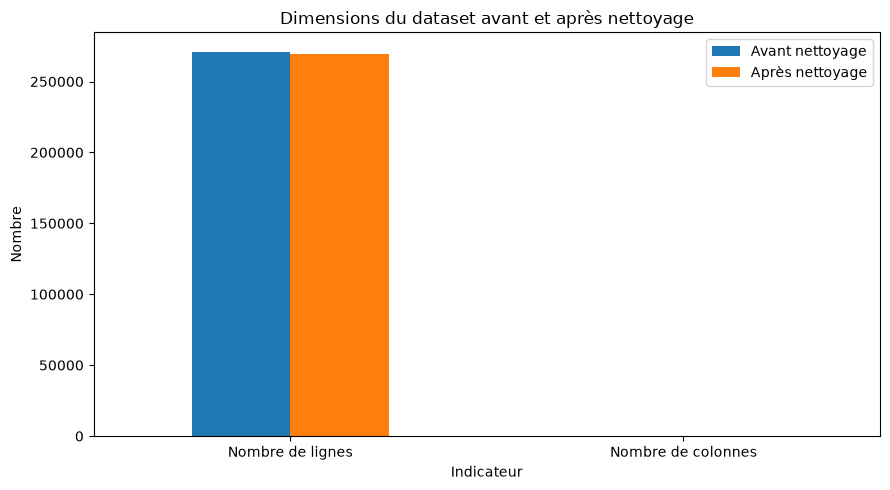

In [20]:
# Visualisation comparative des dimensions du dataset.
fig, ax = plt.subplots(figsize=(9, 5))

comparison.loc[
    ["Nombre de lignes", "Nombre de colonnes"]
].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Dimensions du dataset avant et après nettoyage")
ax.set_ylabel("Nombre")
ax.set_xlabel("Indicateur")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 23. Conclusion générale

Le diagnostic et le nettoyage ont permis d'améliorer la qualité
du jeu de données tout en préservant son contenu historique.

Le fichier initial contenait 271 116 lignes et 15 colonnes.

La suppression des 1 385 occurrences supplémentaires correspondant
à des doublons strictement identiques a produit un dataset final
de **269 731 lignes et 15 colonnes**.

Les valeurs manquantes d'âge, de taille et de poids ont été conservées,
car leur remplacement aurait nécessité des hypothèses non suffisamment
justifiées.

Les valeurs absentes de `Medal` ont également été conservées,
car elles indiquent généralement l'absence de médaille.

Les répétitions métier ont été conservées lorsqu'elles correspondaient
à des informations ou résultats distincts. Enfin, les observations
statistiquement atypiques n'ont pas été supprimées automatiquement.

### Résultat final

Le fichier `data/processed/athlete_events_cleaned.csv` constitue
la version nettoyée du jeu de données.

Cette démarche privilégie la traçabilité des transformations,
la justification des décisions et la préservation des informations
historiques.
